In [2]:
import os
import h5py
import itertools
import numpy as np
import pandas as pd
from pathlib import Path
from utils import data_loader_utils 

In [3]:
machines = ["M01","M02","M03"]
process_names = ["OP00","OP01","OP02","OP03","OP04","OP05","OP06","OP07","OP08","OP09","OP10","OP11","OP12","OP13","OP14"]
labels = ["good","bad"]
path_to_dataset = Path("./data/").absolute()

In [4]:
X_data = []
y_data = []

for process_name, machine, label in itertools.product(process_names, machines, labels):
    data_path = os.path.join(path_to_dataset, machine, process_name, label)
    data_list, data_label = data_loader_utils.load_tool_research_data(data_path, label=label)
    #concatenating
    X_data.extend(data_list)
    y_data.extend(data_label)

loading files from /home/scopellie/EECE5644/CNC_Machining/data/M01/OP00/good... 
skipping /home/scopellie/EECE5644/CNC_Machining/data/M01/OP00/bad empty directory...
loading files from /home/scopellie/EECE5644/CNC_Machining/data/M01/OP00/bad... 
loading files from /home/scopellie/EECE5644/CNC_Machining/data/M02/OP00/good... 
loading files from /home/scopellie/EECE5644/CNC_Machining/data/M02/OP00/bad... 
loading files from /home/scopellie/EECE5644/CNC_Machining/data/M03/OP00/good... 
skipping /home/scopellie/EECE5644/CNC_Machining/data/M03/OP00/bad empty directory...
loading files from /home/scopellie/EECE5644/CNC_Machining/data/M03/OP00/bad... 
loading files from /home/scopellie/EECE5644/CNC_Machining/data/M01/OP01/good... 
loading files from /home/scopellie/EECE5644/CNC_Machining/data/M01/OP01/bad... 
loading files from /home/scopellie/EECE5644/CNC_Machining/data/M02/OP01/good... 
loading files from /home/scopellie/EECE5644/CNC_Machining/data/M02/OP01/bad... 
loading files from /home/

1401 KB


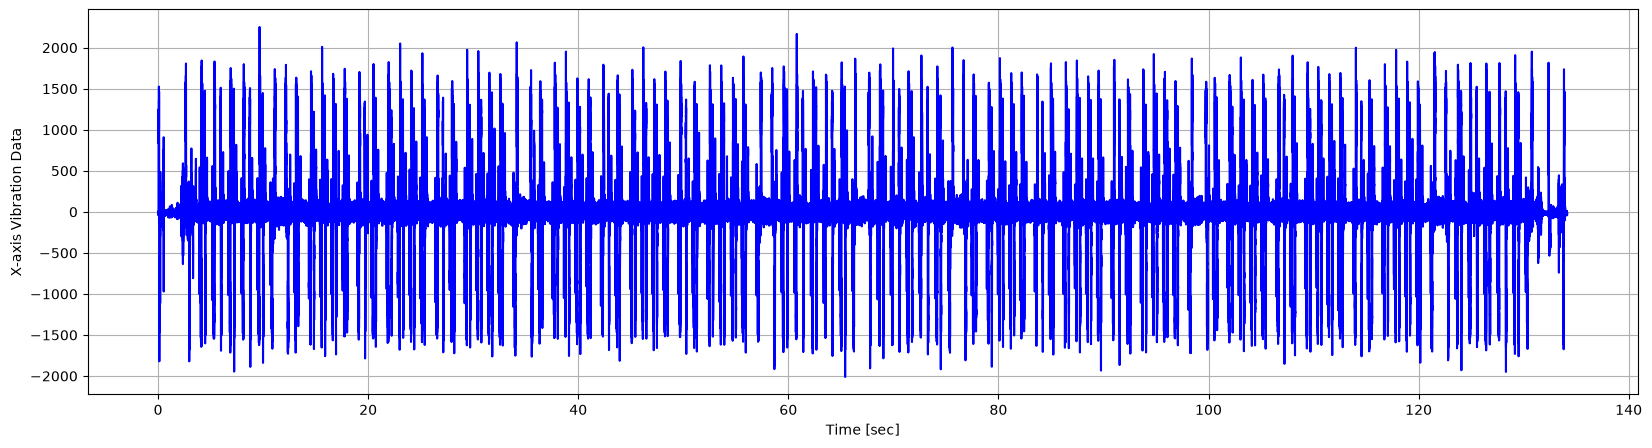

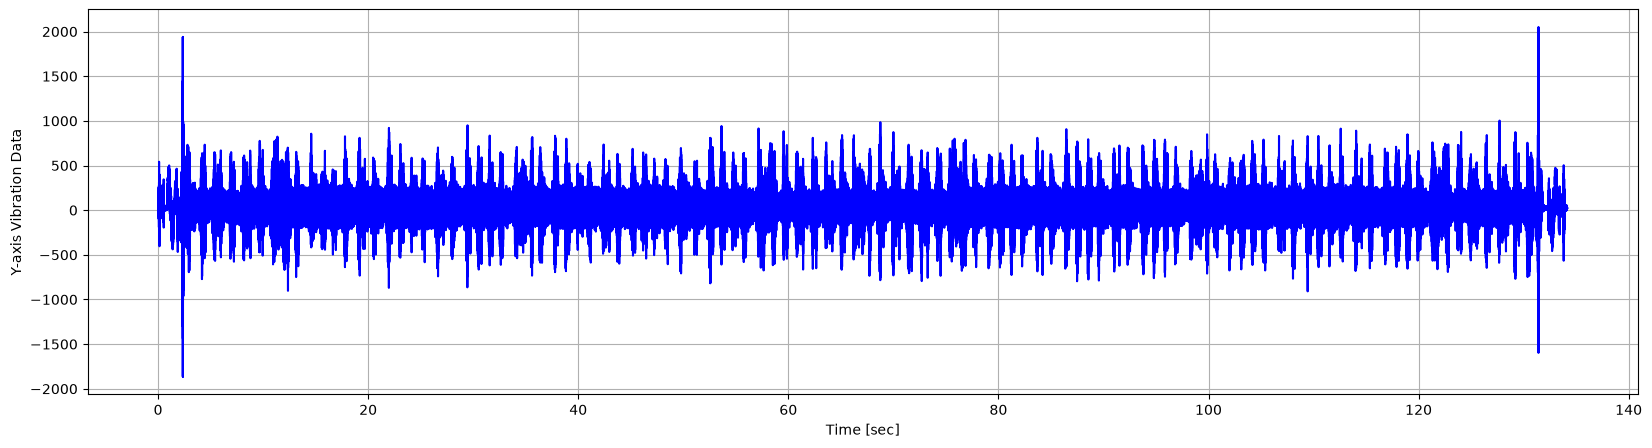

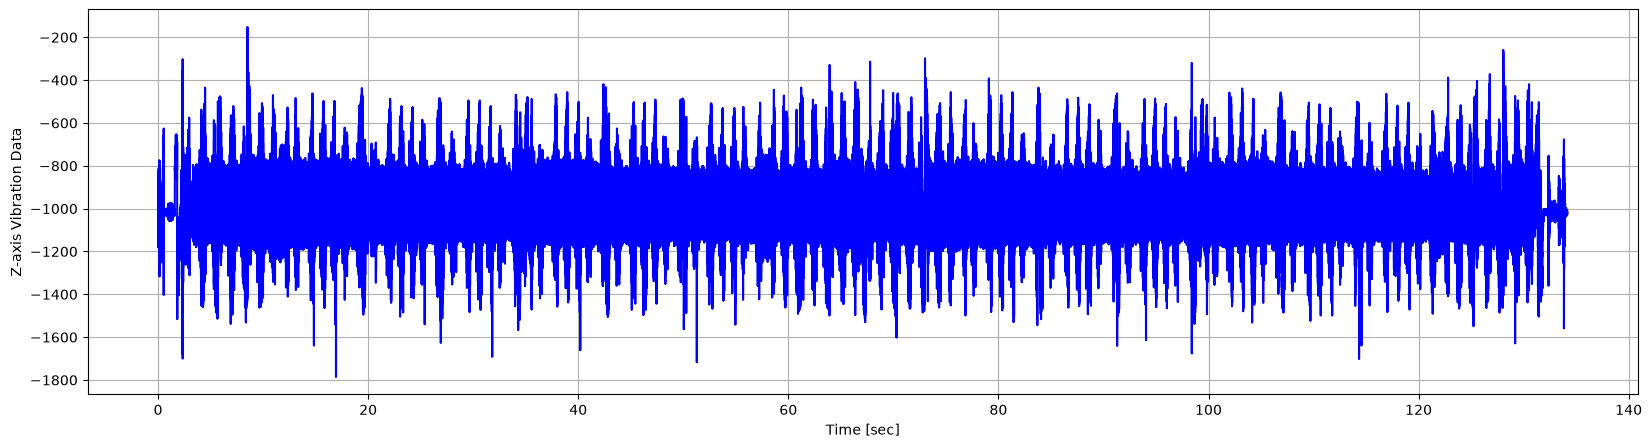

In [5]:
file = Path("./data/M01/OP00/good/M01_Aug_2019_OP00_000.h5").absolute()
print(f"{os.path.getsize(file) / 1024:.0f} KB")
sample = data_loader_utils.datafile_read(file)

In [6]:
! python --version

Python 3.14.4


In [15]:
with h5py.File(file, 'r') as f:
    dataset = f['vibration_data'][:]
    print(len(dataset))
    
    df = pd.DataFrame(dataset, columns=["X","Y","Z"])

summary = df[["X", "Y", "Z"]].agg(['mean', 'std', 'min', 'max'])
print(summary,"\n")
file_name = str(file).split("/")[-1]
label = str(file).split("/")[-2]
df["machine"] = file_name.split("_")[0]
df["label"] = label
df["process"] = file_name.split("_")[3]
print(df.head())

268288
                X            Y            Z
mean    -3.874870    34.393633 -1014.514865
std    469.406993   158.931394   142.390191
min  -2012.000000 -1868.000000 -1786.000000
max   2252.000000  2051.000000  -152.000000 

      X     Y       Z machine label process
0  -9.0   9.0 -1011.0     M01  good    OP00
1 -21.0  19.0 -1011.0     M01  good    OP00
2 -15.0  23.0 -1020.0     M01  good    OP00
3  -9.0  27.0 -1013.0     M01  good    OP00
4  -9.0  17.0 -1020.0     M01  good    OP00


In [ ]:
data_path = Path("./data").absolute()
    
filesumm = data_loader_utils.find_operation_h5s_in_dir(data_path, "OP00", "M01")
print(filesumm)

[('good', 'M01_Aug_2019_OP00_004.h5'), ('good', 'M01_Aug_2019_OP00_005.h5'), ('good', 'M01_Aug_2019_OP00_000.h5'), ('good', 'M01_Aug_2019_OP00_008.h5'), ('good', 'M01_Feb_2021_OP00_007.h5'), ('good', 'M01_Aug_2019_OP00_012.h5'), ('good', 'M01_Aug_2019_OP00_007.h5'), ('good', 'M01_Feb_2019_OP00_000.h5'), ('good', 'M01_Feb_2019_OP00_004.h5'), ('good', 'M01_Feb_2019_OP00_002.h5'), ('good', 'M01_Feb_2019_OP00_001.h5'), ('good', 'M01_Feb_2021_OP00_006.h5'), ('good', 'M01_Aug_2019_OP00_009.h5'), ('good', 'M01_Feb_2021_OP00_009.h5'), ('good', 'M01_Feb_2021_OP00_004.h5'), ('good', 'M01_Feb_2019_OP00_003.h5'), ('good', 'M01_Aug_2019_OP00_011.h5'), ('good', 'M01_Aug_2021_OP00_003.h5'), ('good', 'M01_Aug_2019_OP00_006.h5'), ('good', 'M01_Aug_2019_OP00_003.h5'), ('good', 'M01_Aug_2021_OP00_002.h5'), ('good', 'M01_Aug_2019_OP00_010.h5'), ('good', 'M01_Feb_2020_OP00_002.h5'), ('good', 'M01_Aug_2019_OP00_013.h5'), ('good', 'M01_Feb_2021_OP00_008.h5'), ('good', 'M01_Feb_2021_OP00_005.h5'), ('good', 'M